In [1]:
from pathlib import Path
from PIL import Image, ImageOps

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import json
import random

import torch
import torchvision

from torchvision import transforms
from torchvision.transforms import InterpolationMode

In [2]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
CUDA disponible: False


In [3]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = PROJECT_DIR / "dataset" / "raw" / "cassava_dataset"

REPORTS_DIR = PROJECT_DIR / "reports"
CONFIGS_DIR = PROJECT_DIR / "configs"

SPLITS_PATH = REPORTS_DIR / "dataset_splits.csv"

In [4]:
with open(
    CONFIGS_DIR / "dataset_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

SEED = config["seed"]

NUM_CLASSES = config["dataset_statistics"]["num_classes"]

N_SPLITS = config["cross_validation"]["n_splits"]

CLASS_MAPPING = config["class_mapping"]

print("Semilla:", SEED)
print("Número de clases:", NUM_CLASSES)
print("Número de folds:", N_SPLITS)
print("Mapeo de clases:", CLASS_MAPPING)

Semilla: 42
Número de clases: 5
Número de folds: 3
Mapeo de clases: {'bacterial_blight': 0, 'brown_streak_disease': 1, 'green_mottle': 2, 'healthy': 3, 'mosaic_disease': 4}


In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Semillas configuradas correctamente.")

Semillas configuradas correctamente.


In [6]:
df_splits = pd.read_csv(SPLITS_PATH)

df_development = df_splits[
    df_splits["split"] == "development"
].copy()

df_test = df_splits[
    df_splits["split"] == "test"
].copy()

print("Imágenes de desarrollo:", len(df_development))
print("Imágenes de prueba:", len(df_test))

display(df_development.head())

Imágenes de desarrollo: 18187
Imágenes de prueba: 3210


,filename,filepath,class,extension,width,height,format,mode,size_bytes,sha256,status,error,split,fold
0,2422491518.jpg,mosaic_disease\2422491518.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,124540,568dbafb87aec5908d558598dd7391d0bd6c15e7fd33fd...,valid,NaN,development,3
1,2878596544.jpg,mosaic_disease\2878596544.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,143096,a24b7bc16ac427258d93de3bc06c78625e5eb632ba8f93...,valid,NaN,development,2
2,1696364421.jpg,green_mottle\1696364421.jpg,green_mottle,.jpg,800,600,JPEG,RGB,82996,5037e2d79f82f25519924a581be8cac219bef654cc8957...,valid,NaN,development,3
3,3806158675.jpg,mosaic_disease\3806158675.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,127459,25599e588ba4e49fd8bb6874db71e42da827bee10ba49e...,valid,NaN,development,3
4,1132695066.jpg,mosaic_disease\1132695066.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,110081,000e1d7184525f915868312102bc8f422fdd586594473c...,valid,NaN,development,2


In [7]:
IMAGE_SIZE = (224, 224)

NUM_CHANNELS = 3

MEAN = [0.485, 0.456, 0.406]

STD = [0.229, 0.224, 0.225]

print("Tamaño de imagen:", IMAGE_SIZE)
print("Número de canales:", NUM_CHANNELS)
print("Media:", MEAN)
print("Desviación estándar:", STD)

Tamaño de imagen: (224, 224)
Número de canales: 3
Media: [0.485, 0.456, 0.406]
Desviación estándar: [0.229, 0.224, 0.225]


In [8]:
def load_image(filepath):

    with Image.open(filepath) as img:

        img = ImageOps.exif_transpose(img)

        img = img.convert("RGB")

    return img

Clase: mosaic_disease
Dimensiones: (800, 600)
Modo: RGB


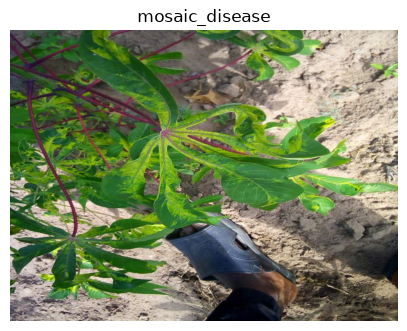

In [9]:
sample = df_development.sample(
    n=1,
    random_state=SEED
).iloc[0]

image_path = DATASET_DIR / sample["filepath"]

image = load_image(image_path)

print("Clase:", sample["class"])
print("Dimensiones:", image.size)
print("Modo:", image.mode)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(sample["class"])
plt.axis("off")
plt.show()

In [10]:
train_transform = transforms.Compose([

    transforms.Resize(
        IMAGE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=15,
        interpolation=InterpolationMode.BILINEAR,
        fill=(124, 116, 104)
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )

])

In [11]:
eval_transform = transforms.Compose([

    transforms.Resize(
        IMAGE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )

])

In [12]:
train_image = train_transform(image)

eval_image = eval_transform(image)

print("Tensor de entrenamiento:")
print("Dimensiones:", train_image.shape)
print("Tipo de dato:", train_image.dtype)

print("\nTensor de evaluación:")
print("Dimensiones:", eval_image.shape)
print("Tipo de dato:", eval_image.dtype)

Tensor de entrenamiento:
Dimensiones: torch.Size([3, 224, 224])
Tipo de dato: torch.float32

Tensor de evaluación:
Dimensiones: torch.Size([3, 224, 224])
Tipo de dato: torch.float32


In [13]:
def denormalize(tensor):

    mean = torch.tensor(
        MEAN,
        dtype=tensor.dtype,
        device=tensor.device
    ).view(3, 1, 1)

    std = torch.tensor(
        STD,
        dtype=tensor.dtype,
        device=tensor.device
    ).view(3, 1, 1)

    image = tensor * std + mean

    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).cpu().numpy()

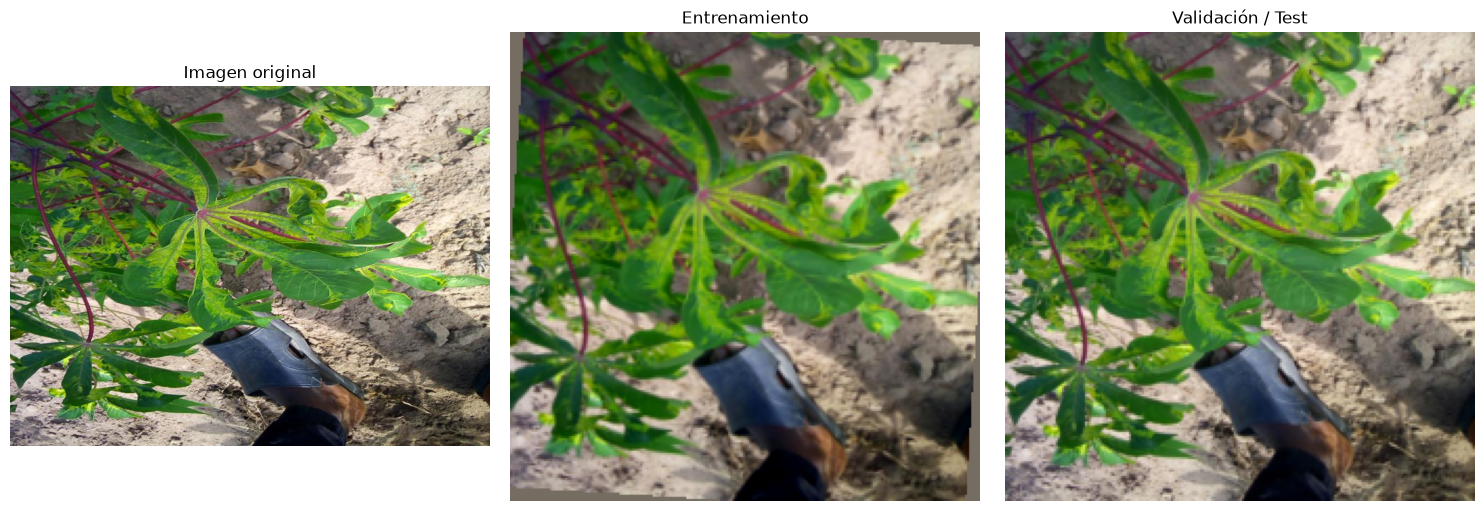

In [14]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(image)
axes[0].set_title("Imagen original")

axes[1].imshow(denormalize(train_image))
axes[1].set_title("Entrenamiento")

axes[2].imshow(denormalize(eval_image))
axes[2].set_title("Validación / Test")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

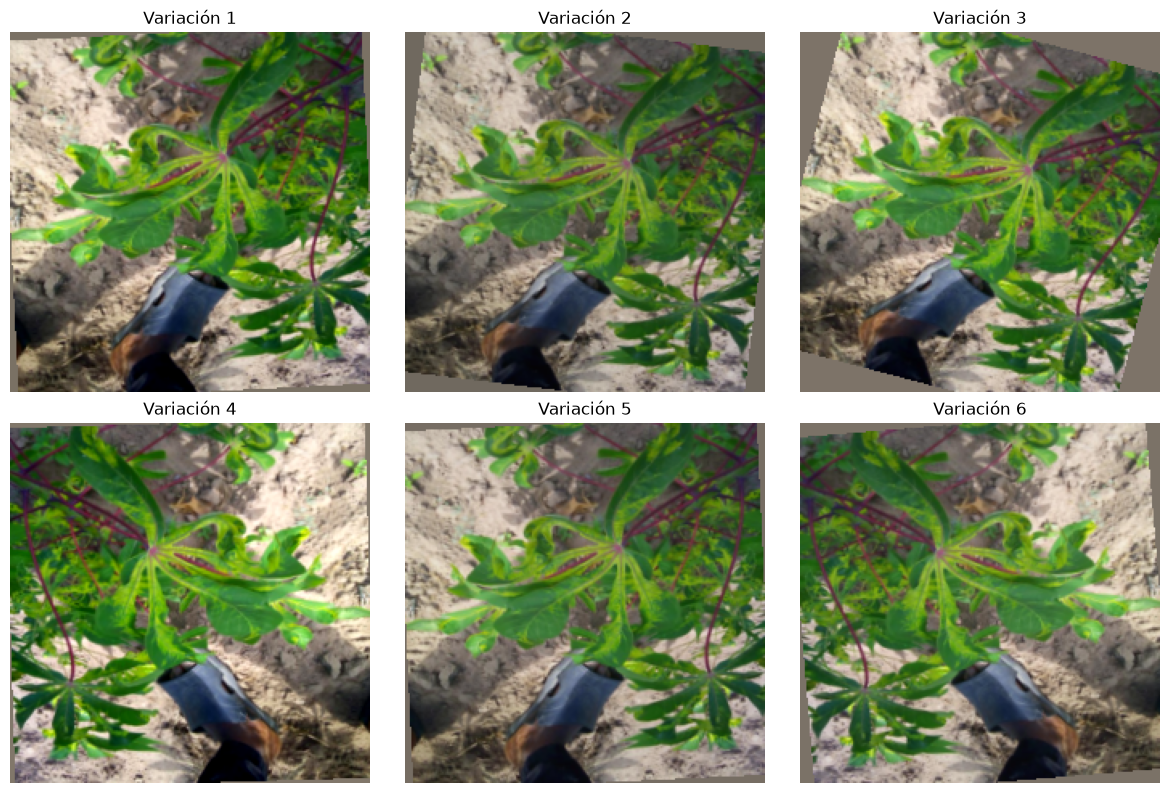

In [15]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 8)
)

for i, ax in enumerate(axes.flat):

    augmented_image = train_transform(image)

    ax.imshow(
        denormalize(augmented_image)
    )

    ax.set_title(f"Variación {i + 1}")

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "augmentation_examples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [16]:
EXPECTED_SHAPE = (3, 224, 224)

assert tuple(train_image.shape) == EXPECTED_SHAPE

assert tuple(eval_image.shape) == EXPECTED_SHAPE

assert train_image.dtype == torch.float32

assert eval_image.dtype == torch.float32

assert torch.isfinite(train_image).all()

assert torch.isfinite(eval_image).all()

print("Todas las verificaciones fueron superadas.")

Todas las verificaciones fueron superadas.


In [17]:
eval_image_1 = eval_transform(image)

eval_image_2 = eval_transform(image)

assert torch.equal(
    eval_image_1,
    eval_image_2
), "El preprocesamiento de evaluación no es determinista."

print("Preprocesamiento de evaluación determinista.")

Preprocesamiento de evaluación determinista.


In [18]:
augmented_images = [
    train_transform(image)
    for _ in range(5)
]

all_equal = all(
    torch.equal(augmented_images[0], img)
    for img in augmented_images[1:]
)

print("Todos los aumentos son iguales:", all_equal)

Todos los aumentos son iguales: False


In [19]:
preprocessing_config = {

    "image_size": list(IMAGE_SIZE),

    "num_channels": NUM_CHANNELS,

    "color_mode": "RGB",

    "exif_transpose": True,

    "resize": {
        "interpolation": "bilinear",
        "antialias": True
    },

    "normalization": {
        "method": "ImageNet",
        "mean": MEAN,
        "std": STD
    },

    "augmentation": {
        "horizontal_flip": 0.5,
        "vertical_flip": 0.5,
        "rotation_degrees": 15,
        "rotation_fill": [124, 116, 104],
        "brightness": 0.1,
        "contrast": 0.1,
        "saturation": 0.05
    },

    "apply_augmentation_to": "train",

    "seed": SEED
}

preprocessing_path = (
    CONFIGS_DIR / "preprocessing_config.json"
)

with open(
    preprocessing_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

print("Configuración guardada:", preprocessing_path)

Configuración guardada: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\configs\preprocessing_config.json
